In [1]:
import glob

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



In [2]:
folder_path = r"C:\Users\Dell\Downloads\archive (27)"
all_file = glob.glob(folder_path + "/*.csv")

df_list = []
for file in all_file:
    df = pd.read_csv(file)
    df.columns = df.columns.str.strip().str.lower().str.replace(' ', '', regex=True)
    df = df.rename(columns={'tax(£)': 'tax'})
    for c in df.select_dtypes(include='object').columns:
        df[c] = df[c].str.strip()
    df_list.append(df)

combined_df = pd.concat(df_list, ignore_index=True)
print(len(all_file), combined_df.shape)
print(combined_df.columns.to_list())
combined_df.to_csv(r"C:\Users\Dell\Downloads\car price.csv", index=False)


9 (99187, 9)
['model', 'year', 'price', 'transmission', 'mileage', 'fueltype', 'tax', 'mpg', 'enginesize']


In [3]:
df=pd.read_csv(r"C:\Users\Dell\Downloads\car price.csv")

In [4]:
df.shape

(99187, 9)

In [5]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99187 entries, 0 to 99186
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         99187 non-null  object 
 1   year          99187 non-null  int64  
 2   price         99187 non-null  int64  
 3   transmission  99187 non-null  object 
 4   mileage       99187 non-null  int64  
 5   fueltype      99187 non-null  object 
 6   tax           99187 non-null  int64  
 7   mpg           99187 non-null  float64
 8   enginesize    99187 non-null  float64
dtypes: float64(2), int64(4), object(3)
memory usage: 6.8+ MB


,model,year,price,transmission,mileage,fueltype,tax,mpg,enginesize
0,A1,2017,12500,Manual,15735,Petrol,150,55.4,1.4
1,A6,2016,16500,Automatic,36203,Diesel,20,64.2,2.0
2,A1,2016,11000,Manual,29946,Petrol,30,55.4,1.4
3,A4,2017,16800,Automatic,25952,Diesel,145,67.3,2.0
4,A3,2019,17300,Manual,1998,Petrol,145,49.6,1.0


In [6]:
df.isna().sum()

model           0
year            0
price           0
transmission    0
mileage         0
fueltype        0
tax             0
mpg             0
enginesize      0
dtype: int64

In [7]:
df.duplicated().sum()
df.drop_duplicates(keep='first',inplace=True)
df.reset_index(drop=True,inplace=True)

In [8]:
print(df.describe())

               year          price        mileage           tax           mpg  \
count  97712.000000   97712.000000   97712.000000  97712.000000  97712.000000   
mean    2017.066870   16773.487555   23219.475499    120.142408     55.205623   
std        2.122993    9868.552222   21060.882301     63.357250     16.181659   
min     1970.000000     450.000000       1.000000      0.000000      0.300000   
25%     2016.000000    9999.000000    7673.000000    125.000000     47.100000   
50%     2017.000000   14470.000000   17682.500000    145.000000     54.300000   
75%     2019.000000   20750.000000   32500.000000    145.000000     62.800000   
max     2060.000000  159999.000000  323000.000000    580.000000    470.800000   

         enginesize  
count  97712.000000  
mean       1.664913  
std        0.558574  
min        0.000000  
25%        1.200000  
50%        1.600000  
75%        2.000000  
max        6.600000  


In [9]:
from sklearn.ensemble import IsolationForest
X=df[['price','tax','mpg']]
iso=IsolationForest(contamination=0.01,n_estimators=100,random_state=10)
z=iso.fit_predict(X)==-1
print("num of iso",int(z.sum()))


num of iso 978


In [10]:
cols_clip=['price','tax','mpg']
for col in cols_clip:
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)
    iqr = q3-q1
    lower=q1-1.5*iqr
    upper=q3+1.5*iqr
    if col in ['price','tax','mpg']:
        lower=max(0,lower)
        df[col]=df[col].clip(lower=lower,upper=upper)
print(df[['price','tax','mpg']].describe())

              price           tax           mpg
count  97712.000000  97712.000000  97712.000000
mean   16313.913619    134.499499     54.671246
std     8152.729615     23.826942     11.517956
min      450.000000     95.000000     23.550000
25%     9999.000000    125.000000     47.100000
50%    14470.000000    145.000000     54.300000
75%    20750.000000    145.000000     62.800000
max    36876.500000    175.000000     86.350000


In [11]:
c=df.select_dtypes(include='object').columns
for col in c:
    print(df[col].value_counts())


model
Fiesta             6509
Golf               4797
Focus              4555
C Class            3694
Corsa              3285
                   ... 
220                   1
Transit Tourneo       1
Ranger                1
Amica                 1
Accent                1
Name: count, Length: 195, dtype: int64
transmission
Manual       55502
Semi-Auto    22296
Automatic    19905
Other            9
Name: count, dtype: int64
fueltype
Petrol      53982
Diesel      40419
Hybrid       3059
Other         246
Electric        6
Name: count, dtype: int64


<Axes: xlabel='fueltype', ylabel='count'>

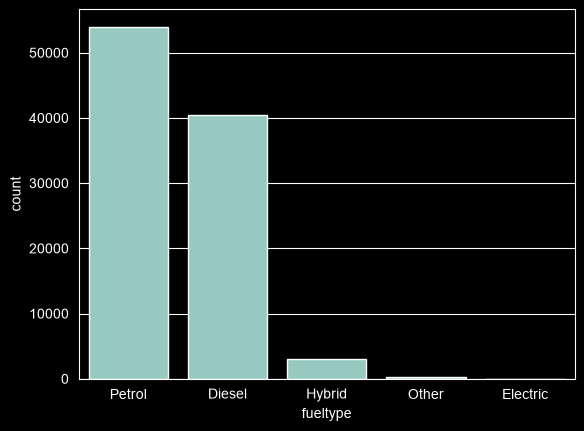

In [12]:
sns.barplot(df['fueltype'].value_counts())


<Axes: xlabel='transmission', ylabel='proportion'>

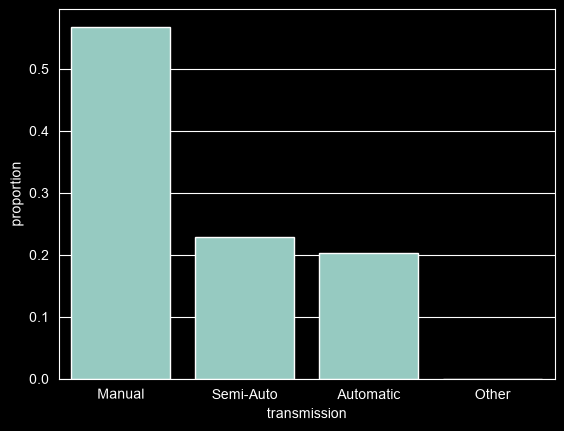

In [13]:
sns.barplot(df['transmission'].value_counts(normalize=True))

<Axes: >

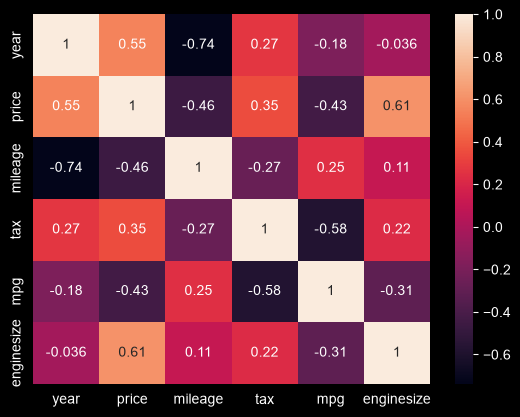

In [14]:
sns.heatmap(df.corr(numeric_only=True),annot=True)


In [15]:
df.corr(numeric_only=True)['price'].drop("price").sort_values(ascending=False)

enginesize    0.611871
year          0.545502
tax           0.352668
mpg          -0.434183
mileage      -0.459715
Name: price, dtype: float64

In [16]:
from sklearn.model_selection import train_test_split, KFold

X=df.drop(['price'],axis=1)
y=df['price']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=10)

In [17]:
from sklearn.preprocessing import StandardScaler,TargetEncoder
from sklearn.model_selection import KFold
encoder={}
kf=KFold(n_splits=5,random_state=10,shuffle=True)

for col in X.select_dtypes(include='object').columns:
    te=TargetEncoder(smooth='auto',cv=kf)
    X_train[[col]]=te.fit_transform(X_train[[col]],y_train)
    X_test[[col]]=te.transform(X_test[[col]])
    encoder[col]=te


In [18]:
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

In [19]:
print(pd.DataFrame(X_train).describe())

                  0             1             2             3             4  \
count  7.816900e+04  7.816900e+04  7.816900e+04  7.816900e+04  7.816900e+04   
mean   1.294391e-16  2.825373e-14  7.126425e-17  1.617989e-17 -8.002684e-16   
std    1.000006e+00  1.000006e+00  1.000006e+00  1.000006e+00  1.000006e+00   
min   -2.317312e+00 -2.216715e+01 -8.631934e-01 -1.102916e+00 -9.077634e-01   
25%   -9.104109e-01 -5.018401e-01 -8.585776e-01 -7.377287e-01 -9.014164e-01   
50%   -7.137128e-02 -3.085512e-02 -8.507712e-01 -2.608633e-01 -8.818262e-01   
75%    6.789224e-01  9.111148e-01  8.765858e-01  4.404513e-01  1.107413e+00   
max    3.202800e+00  2.022150e+01  1.386193e+00  1.423384e+01  1.280868e+00   

                  5             6             7  
count  7.816900e+04  7.816900e+04  7.816900e+04  
mean  -4.312214e-16 -1.051966e-15 -1.308935e-16  
std    1.000006e+00  1.000006e+00  1.000006e+00  
min   -1.658114e+00 -2.703785e+00 -2.993487e+00  
25%   -3.984991e-01 -6.570153e-01 -8.3

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error,r2_score
regressor=LinearRegression()
regressor.fit(X_train,y_train)
y_pred=regressor.predict(X_test)
print(r2_score(y_test,y_pred))



0.8780931840713103


In [26]:
rf=RandomForestRegressor(n_estimators=100,random_state=10,max_depth=15,min_samples_leaf=5,n_jobs=-1)
rf.fit(X_train,y_train)

y_pred=rf.predict(X_test)
print('R2',r2_score(y_test,y_pred))
print(r2_score(y_test,rf.predict(X_test)))
print(r2_score(y_train,rf.predict(X_train)))


R2 0.9615891600840195
0.9615891600840195
0.9746615229712615


In [22]:
import joblib
final_model=rf
artifact={
    'model':final_model,
    'encoders':encoder,
    'scaler':sc,
    'features':list(X.columns),
}
joblib.dump(artifact,'car_price_model.pkl',compress=3)
print("saving model")


saving model


In [23]:
import os
size=os.path.getsize('car_price_model.pkl')/(1024*1024)
print(f"{size} MB")

95.01526641845703 MB


In [24]:
load=joblib.load('car_price_model.pkl')
print(load.keys())
print(type(load))

dict_keys(['model', 'encoders', 'scaler', 'features'])
<class 'dict'>


In [25]:
import gradio as gr
import joblib
import pandas as pd

# 1. تحميل الموديل والأدوات المحفوظة
bundle = joblib.load("car_price_model.pkl")
model = bundle["model"]
encoders = bundle["encoders"]
scaler = bundle["scaler"]
features = bundle["features"]

# 2. قوائم الاختيارات للـ Dropdowns
if "df" in globals():
  models_list = sorted(df["model"].astype(str).str.strip().unique().tolist())
  trans_list = sorted(
      df["transmission"].astype(str).str.strip().unique().tolist()
  )
  fuel_list = sorted(df["fueltype"].astype(str).str.strip().unique().tolist())
else:
  models_list = ["Golf", "Polo", "Passat", "Tiguan", "Fiesta", "Focus", "Beetle"]
  trans_list = ["Manual", "Automatic", "Semi-Auto"]
  fuel_list = ["Petrol", "Diesel", "Hybrid", "Electric"]


# 3. دالة التنبؤ
def predict_car_price(
    model_name, year, mileage, tax, mpg, enginesize, transmission, fueltype
):
  input_df = pd.DataFrame([{
      "model": str(model_name).strip(),
      "year": int(year),
      "mileage": float(mileage),
      "tax": float(tax),
      "mpg": float(mpg),
      "enginesize": float(enginesize),
      "transmission": str(transmission).strip(),
      "fueltype": str(fueltype).strip(),
  }])

  for col, enc in encoders.items():
    if col in input_df.columns:
      input_df[col] = enc.transform(input_df[[col]])

  input_df = input_df[features]
  input_scaled = scaler.transform(input_df)
  pred_price = model.predict(input_scaled)[0]

  return (
      f"### £ {pred_price:,.2f}\n"
      f"**الموديل:** {model_name} | **السنة:** {int(year)} | **الممشى:**"
      f" {int(mileage):,} mi"
  )


# 4. تصميم الواجهة بـ gr.Blocks
custom_css = """
.gradio-container { max-width: 980px !important; margin: auto !important; }
.result-box { border: 1px solid #3b82f6; border-radius: 12px; padding: 16px; }
"""

with gr.Blocks(theme=gr.themes.Soft(), css=custom_css) as demo:
  gr.Markdown("# 🚗 نظام توقع أسعار السيارات\nتقدير فوري للسعر باستخدام نموذج **Random Forest** (بيانات سوق السيارات البريطاني).")

  with gr.Row():
    with gr.Column(scale=1):
      gr.Markdown("### 📋 البيانات الأساسية")
      model_input = gr.Dropdown(
          choices=models_list,
          value=models_list[0] if models_list else None,
          label="الموديل (Model)",
      )
      year_input = gr.Number(label="سنة الصنع (Year)", value=2019, precision=0)
      mileage_input = gr.Number(label="الممشى (Mileage)", value=22000)
      trans_input = gr.Dropdown(
          choices=trans_list,
          value=trans_list[0] if trans_list else None,
          label="ناقل الحركة (Transmission)",
      )

    with gr.Column(scale=1):
      gr.Markdown("### ⚙️ المواصفات الفنية")
      fuel_input = gr.Dropdown(
          choices=fuel_list,
          value=fuel_list[0] if fuel_list else None,
          label="نوع الوقود (Fuel Type)",
      )
      engine_input = gr.Number(
          label="سعة المحرك باللتر (Engine Size)", value=1.6
      )
      mpg_input = gr.Number(label="استهلاك الوقود (MPG)", value=52.0)
      tax_input = gr.Number(label="الضريبة السنوية (Tax)", value=145)

  predict_btn = gr.Button("🔍 احسب السعر المتوقع", variant="primary", size="lg")

  with gr.Group(elem_classes="result-box"):
    gr.Markdown("### 💰 السعر التقديري")
    output_box = gr.Markdown(
        "أدخل بيانات السيارة واضغط على **احسب السعر المتوقع** لعرض النتيجة."
    )

  gr.Examples(
      examples=[
          ["Golf", 2019, 18000, 145, 55.0, 1.5, "Manual", "Petrol"],
          ["Polo", 2017, 35000, 20, 60.0, 1.0, "Manual", "Petrol"],
          ["Tiguan", 2020, 15000, 150, 44.0, 2.0, "Automatic", "Diesel"],
      ],
      inputs=[
          model_input,
          year_input,
          mileage_input,
          tax_input,
          mpg_input,
          engine_input,
          trans_input,
          fuel_input,
      ],
      outputs=output_box,
      fn=predict_car_price,
      cache_examples=False,
      label="أمثلة سريعة للتجربة",
  )

  predict_btn.click(
      fn=predict_car_price,
      inputs=[
          model_input,
          year_input,
          mileage_input,
          tax_input,
          mpg_input,
          engine_input,
          trans_input,
          fuel_input,
      ],
      outputs=output_box,
  )

demo.launch()

C:\Users\Dell\AppData\Local\Temp\ipykernel_29504\3583757142.py:61: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), css=custom_css) as demo:


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
